# Portfolio Diversification Efficiency Challenge

**Role:** You are a financial adviser working for a wealth-management firm. Your client wants to hold as few individual stocks as possible while maintaining a level of diversification comparable to a strong benchmark portfolio.

Your job is to **find the smallest equal-weight portfolio that meets a fixed volatility target**. Choosing the stocks intelligently is more important than simply including a large number of stocks.

## Competition rules

- Choose **5 to 30 different stocks**, all from the provided `SP500_comp_data.xlsx` dataset.
- **Data cleaning:** Exclude stocks with more than **20% missing price observations**. After removing these stocks, delete all dates containing missing prices in any of the remaining stocks. All portfolios must use this same cleaned dataset.
- Use **equal weights**: each chosen stock has weight `1/K`, where `K` is the number of stocks.
- Calculate **daily log returns** from the cleaned prices.
- Calculate **annualized sample volatility** using `daily_return.std(ddof=1) * sqrt(252)`.
- Your portfolio must have **annualized volatility no greater than 13.412377%**.
- **First ranking criterion:** the *fewest stocks* among qualifying portfolios.
- **Tie-breaker:** the *lowest annualized volatility* among portfolios with the same number of stocks.
- You may design and implement **your own selection method**.

## What to submit

Report:

1. The selected stock tickers in alphabetical order.
2. The number of stocks in your portfolio.
3. The annualized portfolio volatility (%).
4. A brief explanation of your selection method.

**Interpretation:** The challenge evaluates historical risk on one fixed sample, not future investment performance.


## 1. Get the dataset and prepare the returns

**Data file:** `SP500_comp_data.xlsx`, the same Excel dataset used in the portfolio-diversification lesson. Download the file from the course material / instructor-provided GitHub repository and keep the **original file unchanged**.

**Running locally (Jupyter or VS Code):** put the file in `data/`, `../data/`, or next to this notebook. The next cell checks these locations automatically. If you keep the file elsewhere, change `DATA_PATH`.

**Running in Google Colab:** upload the Excel file using the Files panel on the left, or execute:

```python
from google.colab import files
files.upload()  # Select SP500_comp_data.xlsx
```

Then run the data cell below. Uploads to Colab's temporary runtime disappear when the runtime is reset.

**Important:** We use *exactly the same dates* for every candidate. After discarding incomplete price dates, returns are calculated once; individual portfolio searches must **not** silently change the sample. All prices must be positive.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:

# Download prices directly from GitHub
url = "https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_2_Carteras_Intro/data/SP500_comp_data.xlsx"

prices = pd.read_excel(url, index_col="Date")

# Prepare the price data
prices.index = pd.to_datetime(prices.index)
prices = prices.sort_index().apply(pd.to_numeric, errors="coerce")
prices = prices.where(prices > 0)

# Remove stocks with more than 20% missing prices
n_stocks_initial = prices.shape[1]
prices = prices.loc[:, prices.isna().mean() <= 0.20]

# Remove all remaining rows with missing prices
prices = prices.dropna()

# Calculate daily log returns
returns = np.log(prices / prices.shift(1)).dropna()



In [3]:


# Locate the course dataset. In Colab, upload it next to the notebook.
locations = [Path("data/SP500_comp_data.xlsx"),
             Path("../data/SP500_comp_data.xlsx"),
             Path("SP500_comp_data.xlsx")]
DATA_PATH = next((p for p in locations if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Download or upload SP500_comp_data.xlsx first.")

prices = pd.read_excel(DATA_PATH, index_col="Date")
prices.index = pd.to_datetime(prices.index)
prices = prices.sort_index().apply(pd.to_numeric, errors="coerce")
prices = prices.dropna(axis=1, how="all").where(lambda x: x > 0)
prices = prices.dropna()  # Fixed common price dates for all assets
returns = np.log(prices / prices.shift(1)).dropna()

MIN_K, MAX_K = 5, 30
REFERENCE_VOL = 0.07963123     # 7.963123% annualized
VOL_LIMIT = 0.08042754         # 8.042754% annualized (fixed competition value)

print(f"Dataset: {DATA_PATH}")
print(f"Stocks: {returns.shape[1]} | Return dates: {len(returns)}")
print(f"Sample: {returns.index.min().date()} to {returns.index.max().date()}")
print(f"Allowed K: {MIN_K} to {MAX_K}; volatility limit: {VOL_LIMIT:.6%}")
assert returns.shape[1] >= MAX_K and len(returns) >= 3


Dataset: ..\data\SP500_comp_data.xlsx
Stocks: 501 | Return dates: 170
Sample: 2022-12-16 to 2023-08-22
Allowed K: 5 to 30; volatility limit: 8.042754%


## 2. Choose a search method

You must select a subset of stocks, not optimize unequal portfolio weights. Suggested ideas:

- **Low volatility:** begin with stocks that individually have the lowest standard deviations.
- **Low correlation:** start from a low-volatility stock and add stocks with low average correlation to those already selected.
- **Greedy minimum portfolio volatility:** try each available stock and choose the one that minimizes the volatility of the new equal-weight portfolio.
- **Swap improvement:** after choosing `K` stocks, replace one selected stock with an unselected stock whenever doing so lowers portfolio volatility.

**Why correlation is not sufficient:** portfolio volatility depends on both individual stock volatilities and their covariances. The lowest-correlation stock need not be the best addition.

A greedy method and swaps are **heuristics**: they do not guarantee finding the best subset. Consider multiple initial stocks or other methods if you want to improve the result.


## 3. Evaluate your candidate fairly

For a subset of `K` selected stocks, calculate the daily equal-weight portfolio returns and annualized volatility:

$
r_{P,t}=\frac{1}{K}\sum_{i=1}^{K}r_{i,t},\qquad
\sigma_{P,ann}=\operatorname{SD}(r_{P,t})\sqrt{252}.
$

With `cov = returns.cov()`, an equivalent, faster calculation is:

$
\sigma_{P,ann}=\sqrt{252\,\operatorname{Mean}(\Sigma_S)},
$

where `Mean(Σ_S)` is the mean of **all entries** of the selected covariance submatrix (including its diagonal). These expressions agree because weights are equal and all returns use the same dates.


## 4. Instructor solution — Compare the three search strategies

The code below uses the covariance matrix on the **fixed common sample** for efficient subset evaluation. It constructs low-volatility and forward-selection portfolios, tries several starting stocks, then improves candidates with swaps. The solution is intended as a **reproducible heuristic baseline**, not a proof of optimality.


In [4]:
from tqdm import tqdm

tickers = list(returns.columns)
n = len(tickers)
cov = returns.cov().to_numpy()
corr = returns.corr().to_numpy()
variances = np.diag(cov)

# Lower variance and ticker index break ties deterministically.
low_vol_order = np.lexsort((np.arange(n), variances))
start_stocks = low_vol_order[:min(5, n)]  # Try different initial stocks.


def volatility(selected):
    """Annualized volatility of an equal-weight portfolio."""
    selected = np.asarray(selected, dtype=int)
    return float(np.sqrt(max(0, 252 * cov[np.ix_(selected, selected)].mean())))


def forward_path(start, method, max_k):
    """Construct nested portfolios, one stock at a time."""
    selected = [int(start)]
    path = {}
    while len(selected) < max_k:
        remaining = np.array([j for j in range(n) if j not in selected])
        if method == "Low correlation":
            quality = np.nanmean(corr[np.ix_(remaining, selected)], axis=1)
        else:
            # Equal weights: minimizing variance = minimizing sum of covariances.
            current_total = cov[np.ix_(selected, selected)].sum()
            quality = current_total + 2 * cov[np.ix_(remaining, selected)].sum(axis=1) + variances[remaining]
        selected.append(int(remaining[np.argmin(quality)]))
        if len(selected) >= MIN_K:
            path[len(selected)] = selected.copy()
    return path


def improve_swaps(selected, max_rounds=15):
    """Reduce variance by swapping one chosen stock with one unused stock."""
    selected = list(selected)
    K = len(selected)
    for _ in range(max_rounds):
        remaining = np.array([j for j in range(n) if j not in selected])
        if len(remaining) == 0:
            break

        current = cov[np.ix_(selected, selected)].sum()
        sums_selected = cov[np.ix_(selected, selected)].sum(axis=1)
        sums_remaining = cov[np.ix_(remaining, selected)].sum(axis=1)

        # For each replacement: remove the old stock's terms and add new terms.
        # Rows = unused stocks; columns = positions to replace.
        trials = (current
                  - 2 * sums_selected[None, :] + variances[np.asarray(selected)][None, :]
                  + 2 * (sums_remaining[:, None] - cov[np.ix_(remaining, selected)])
                  + variances[remaining, None])
        r, p = np.unravel_index(np.argmin(trials), trials.shape)
        if trials[r, p] >= current - 1e-12:
            break
        selected[p] = int(remaining[r])
    return sorted(selected)


# Construct complete forward paths once; reuse their portfolios for every K.
paths = {
    (method, int(start)): forward_path(start, method, MAX_K)
    for method in ["Low correlation", "Minimum portfolio volatility"]
    for start in start_stocks
}

records = []
for K in tqdm(range(MIN_K, MAX_K + 1), desc="Portfolio sizes"):
    candidates = {"Low volatility": list(low_vol_order[:K])}

    for method in ["Low correlation", "Minimum portfolio volatility"]:
        # Best starting point for this K, before swaps.
        candidates[method] = min(
            (paths[(method, int(s))][K] for s in start_stocks),
            key=volatility
        )

    # Improve every strategy; consider all starting points for greedy search.
    improved = []
    for method, subset in candidates.items():
        improved.append((method + " + swaps", improve_swaps(subset)))
    for method in ["Low correlation", "Minimum portfolio volatility"]:
        for start in start_stocks:
            improved.append((method + " + swaps (multistart)",
                             improve_swaps(paths[(method, int(start))][K])))

    best_method, best_stocks = min(improved, key=lambda item: volatility(item[1]))
    row = {
        "K": K,
        "Low volatility (%)": 100 * volatility(candidates["Low volatility"]),
        "Low correlation (%)": 100 * volatility(candidates["Low correlation"]),
        "Greedy min-vol (%)": 100 * volatility(candidates["Minimum portfolio volatility"]),
        "Best after swaps (%)": 100 * volatility(best_stocks),
        "Winning method": best_method,
        "Tickers": ",".join(sorted(tickers[j] for j in best_stocks)),
    }
    records.append(row)

results = pd.DataFrame(records)
display(results.head(10).round(4))


Portfolio sizes: 100%|██████████| 26/26 [00:00<00:00, 30.16it/s]


,K,Low volatility (%),Low correlation (%),Greedy min-vol (%),Best after swaps (%),Winning method,Tickers
0,5,10.9161,13.8392,9.4554,9.2790,Low correlation + swaps (multistart),"ABBV,DRI,HSY,TMUS,V"
1,6,10.9932,12.4482,9.1711,8.9776,Low correlation + swaps,"ABBV,DRI,HSY,LMT,TMUS,VRSN"
2,7,11.0338,13.8118,8.9895,8.8188,Minimum portfolio volatility + swaps (multistart),"BMY,CPRT,DRI,HSY,KDP,LMT,TMUS"
3,8,10.9136,12.2280,8.8598,8.6492,Low volatility + swaps,"BMY,CBOE,DRI,KDP,KR,LMT,SNPS,TMUS"
4,9,10.4776,12.0977,8.7522,8.4458,Low volatility + swaps,"ABC,BMY,CBOE,DRI,KDP,KR,LMT,SNPS,VZ"
5,10,10.1234,12.7037,8.6579,8.3572,Minimum portfolio volatility + swaps (multistart),"ABC,BMY,CBOE,DRI,KDP,KR,LMT,MO,SNPS,VZ"
6,11,10.0339,12.1119,8.5827,8.2960,Low volatility + swaps,"BMY,DRI,HSY,INCY,KDP,KR,LMT,MCK,SNPS,TMUS,ZBH"
7,12,10.0531,12.3526,8.5217,8.2046,Low volatility + swaps,"CBOE,DRI,HSY,INCY,KDP,KO,KR,LMT,MCK,SNPS,TMUS,WST"
8,13,9.8871,11.5616,8.4607,8.1544,Low volatility + swaps,"CBOE,DRI,HSY,IBM,INCY,KDP,KO,KR,LMT,MCK,SNPS,T..."
9,14,9.9488,11.6457,8.3889,8.1206,Minimum portfolio volatility + swaps,"BMY,CBOE,DRI,HSY,INCY,KDP,KR,LMT,MCK,MO,SNPS,T..."


## 5. Select and verify the competition winner

We only consider portfolios with `K = 5, ..., 30` and an annualized volatility below the **fixed** target. Rank first by `K`, then by risk. Recalculate the final risk directly from the daily returns; this catches implementation or weighting mistakes.

The previously reported 18-stock qualifying subset is a useful cross-check, but another run may identify a smaller or lower-risk portfolio. The fixed target does not change when the search improves.


In [5]:
# Find the fewest assets meeting the fixed risk ceiling
qualifying = results[results["Best after swaps (%)"] <= 100 * VOL_LIMIT + 1e-10]
if qualifying.empty:
    print("No qualifying portfolio found. Try additional starting stocks or searches.")
else:
    winner = qualifying.sort_values(["K", "Best after swaps (%)"]).iloc[0]
    chosen = winner["Tickers"].split(",")
    K = len(chosen)

    # Independently verify the portfolio with daily returns
    vol_check = returns[chosen].mean(axis=1).std(ddof=1) * np.sqrt(252)
    assert len(set(chosen)) == K and MIN_K <= K <= MAX_K
    assert np.isclose(vol_check, winner["Best after swaps (%)"] / 100, atol=1e-10)
    assert vol_check <= VOL_LIMIT + 1e-8

    print("SELECTED PORTFOLIO")
    print("Tickers:", ",".join(sorted(chosen)))
    print(f"Number of stocks: {K}")
    print(f"Annualized volatility: {vol_check:.6%}")
    print(f"Fixed volatility limit: {VOL_LIMIT:.6%}")
    print("Search method:", winner["Winning method"])


SELECTED PORTFOLIO
Tickers: ABBV,ABC,CAG,CBOE,CME,CMG,DRI,HSY,IBM,INCY,KDP,KR,LLY,LMT,MO,SNPS,TMUS,WST
Number of stocks: 18
Annualized volatility: 8.028033%
Fixed volatility limit: 8.042754%
Search method: Minimum portfolio volatility + swaps (multistart)


## 6. Compare portfolio risk against the number of stocks

The chart makes clear whether more holdings materially improve risk reduction. With equal weights, the best heuristic volatility for **exactly** `K` holdings need not decrease monotonically as `K` rises. That is why we evaluate each permitted size separately.


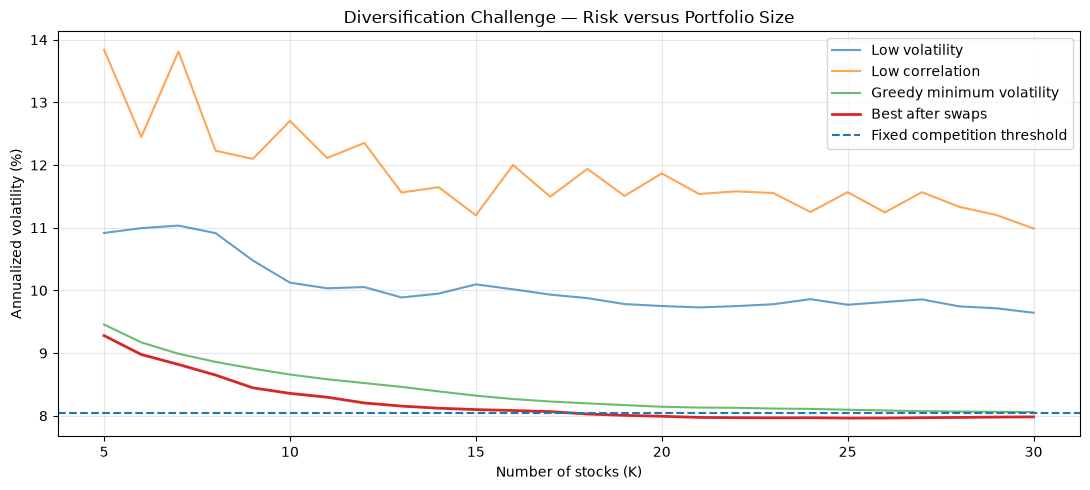

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(results["K"], results["Low volatility (%)"], label="Low volatility", alpha=0.7)
ax.plot(results["K"], results["Low correlation (%)"], label="Low correlation", alpha=0.7)
ax.plot(results["K"], results["Greedy min-vol (%)"], label="Greedy minimum volatility", alpha=0.7)
ax.plot(results["K"], results["Best after swaps (%)"], label="Best after swaps", linewidth=2)
ax.axhline(100 * VOL_LIMIT, linestyle="--", label="Fixed competition threshold")
ax.set(title="Diversification Challenge — Risk versus Portfolio Size",
       xlabel="Number of stocks (K)", ylabel="Annualized volatility (%)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## 7. Export results for instructor review

The file contains all best-found portfolios at each allowed size, including a ticker list. It can be shared for checking the competition rule or refining search methods.


In [7]:
results.to_csv("portfolio_challenge_5_to_30_results.csv", index=False, float_format="%.8f")
print("Saved portfolio_challenge_5_to_30_results.csv")


Saved portfolio_challenge_5_to_30_results.csv


## 4. Submission and client recommendation

Submit the **stock symbols in alphabetical order**, with `K` and the annualized volatility in percent. Save the code that reproduces your selection. Explain briefly how you searched, whether you improved your solution, and why choosing a few low-correlation stocks alone may not minimize portfolio risk.

**Verification:** your answer is admissible only if all symbols occur in the supplied data, no symbol is repeated, `5 <= K <= 30`, weights are equal and the annualized volatility computed from the fixed `returns` is at most **8.042754%**. The instructor can independently recompute this statistic from the ticker list.

**Questions for the financial adviser:** How much volatility was sacrificed to reduce the number of holdings? Why might the solution change on a different historical sample? What practical considerations (costs, concentration, estimation risk) are not captured by the historical volatility criterion?
